# Optical Flow
## Sparse Optical Flow

As always start by importing the relevant packages.

In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

Load the images `OF1.jpg` and `OF2.jpg` and change them to grayscale.

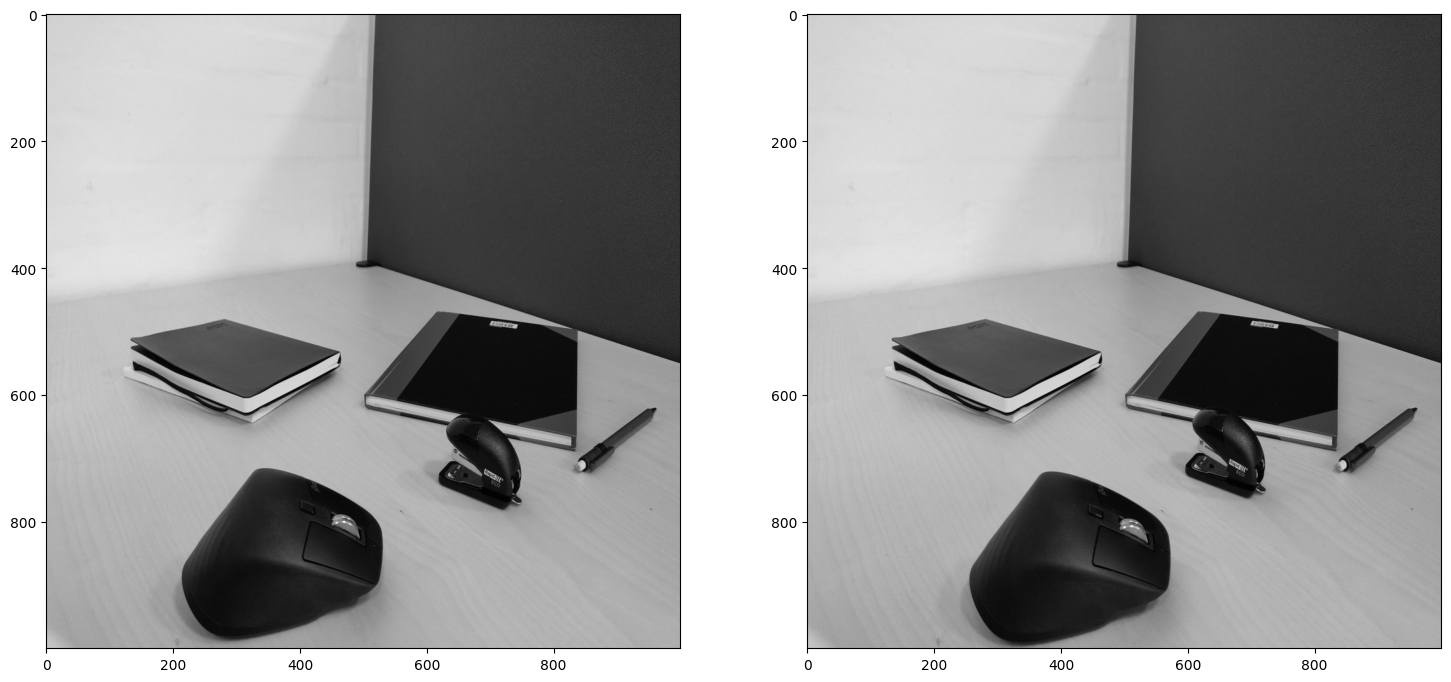

In [ ]:
# Load two frames that capture a scene at two points in time, convert both to
# RGB for display and to grayscale for processing. Optical flow works by comparing
# consecutive frames to estimate how pixels/features have moved between them,
# so we need both images loaded together. cv2.imread() loads in BGR order, but
# matplotlib expects RGB, so each image's channels are split and re-merged in
# reversed order for correct display colors. Both optical flow functions used
# later (calcOpticalFlowPyrLK and calcOpticalFlowFarneback) operate on
# single-channel intensity images, not color. plt.subplot(1,2,1) / (1,2,2)
# plots the two grayscale frames side by side in one figure, so we can visually
# compare them and see how subtle the differences between frames are.
img1 = cv2.imread('OF1.jpg')
img2 = cv2.imread('OF2.jpg')

# Changing the order from bgr to rgb so that matplotlib can show it.
b,g,r = cv2.split(img1)
img1 = cv2.merge([r,g,b])
# Changing the order from bgr to rgb so that matplotlib can show it.
b,g,r = cv2.split(img2)
img2 = cv2.merge([r,g,b])

gray1 = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_RGB2GRAY)

plt.figure(figsize = (18,18))
plt.subplot(1,2,1)
plt.imshow(gray1, cmap = 'gray')
plt.subplot(1,2,2)
plt.imshow(gray2, cmap = 'gray')

They look pretty much the same. We can now use optical flow to find out how the objects in the picutures have moved. We do this by first using [`cv2.goodFeaturesToTrack`](https://docs.opencv.org/4.7.0/dd/d1a/group__imgproc__feature.html#ga1d6bb77486c8f92d79c8793ad995d541) to find features in the first image. You can play around with the parameters to see the difference.

In [ ]:
# Detect good features to track in the first frame. Sparse optical flow doesn't
# track every pixel. It only tracks a selected set of distinctive points (e.g.
# corners), since these are easier to reliably re-locate in the next frame than
# a flat, featureless patch of the image. cv2.goodFeaturesToTrack() finds exactly
# this kind of distinctive point.
#   maxCorners=100: track at most the 100 strongest features.
#   qualityLevel=0.3: only keep features whose quality score is at least 30% of
#     the single best feature found, keeping only strong, unambiguous corners
#     which tend to track more reliably.
#   minDistance=7: require at least 7 pixels between any two selected features,
#     so tracked points are somewhat spread out rather than clustered in one spot.
feat1 = cv2.goodFeaturesToTrack(gray1, maxCorners=100, qualityLevel=0.3, minDistance=7)

Next we use the function [`cv2.calcOpticalFlowPyrLK`](https://docs.opencv.org/4.7.0/dc/d6b/group__video__track.html#ga473e4b886d0bcc6b65831eb88ed93323) to track the features in the next image.

In [4]:
# Track the detected features from the first frame into the second frame using
# the Lucas-Kanade sparse optical flow method. cv2.calcOpticalFlowPyrLK() takes
# the pixel locations we found in frame 1 (feat1) and searches frame 2 for where
# each of those same points has moved to, using a pyramidal (multi-scale)
# implementation of the Lucas-Kanade algorithm, which makes it robust to both
# small and larger displacements between frames.
#   feat2: the estimated new (x, y) location of each input feature in the
#     second image.
#   status: a flag per feature indicating whether it was successfully tracked (1)
#     or lost (0).
#   error: an error/confidence measure per feature, indicating how good the match is.
feat2, status, error = cv2.calcOpticalFlowPyrLK(gray1, gray2, feat1, None)

We now have the location of the features from the first image in the second image. To find the movement, we can draw a line between the keypoints.

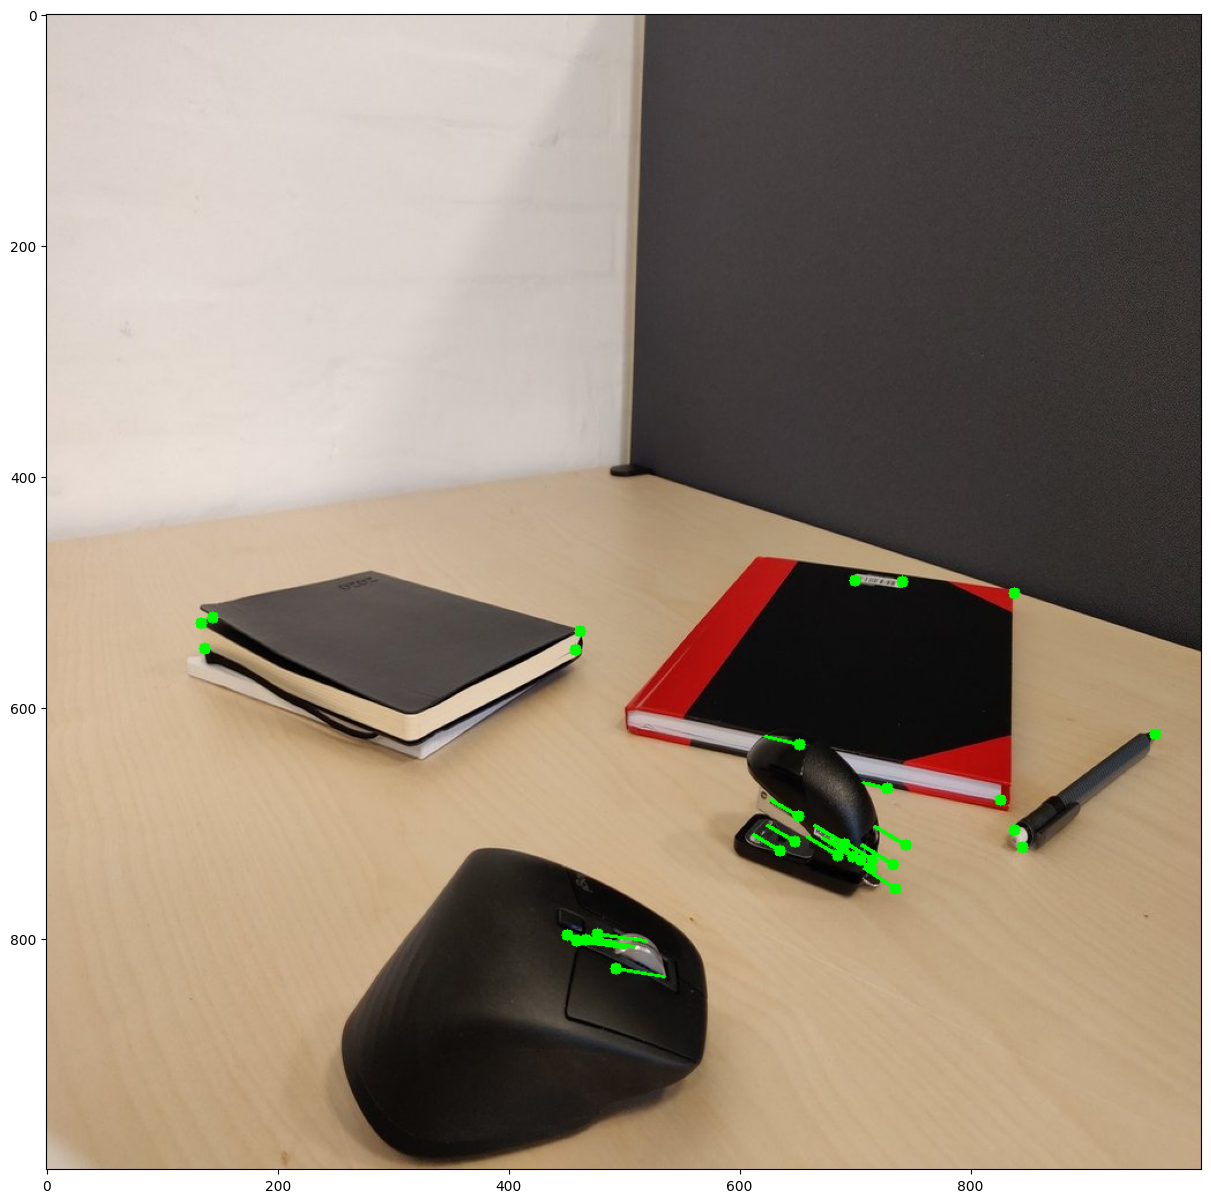

In [5]:
# Visualize the raw optical flow result by drawing a line from each feature's
# old position (frame 1) to its new position (frame 2). Connecting each point's
# start and end location directly shows the direction and magnitude of its
# estimated motion. A longer line means more movement was detected for that point.
# For each tracked feature, extract its (x, y) coordinates in both frames
# (feat1[i], feat2[i]) as integers (pixel coordinates must be whole numbers for
# drawing), then draw a green line connecting them plus a filled green circle
# marking the starting point, directly onto the second frame's image (img2) for
# context.
for i in range(len(feat1)):
    f10=int(feat1[i][0][0])
    f11=int(feat1[i][0][1])
    f20=int(feat2[i][0][0])
    f21=int(feat2[i][0][1])
    cv2.line(img2, (f10,f11), (f20, f21), (0, 255, 0), 2)
    cv2.circle(img2, (f10, f11), 5, (0, 255, 0), -1)

plt.figure(figsize=(15,15))
plt.imshow(img2)

## Exercise 4a
Change the code such that only the keypoints that have moved will be showed in the image.


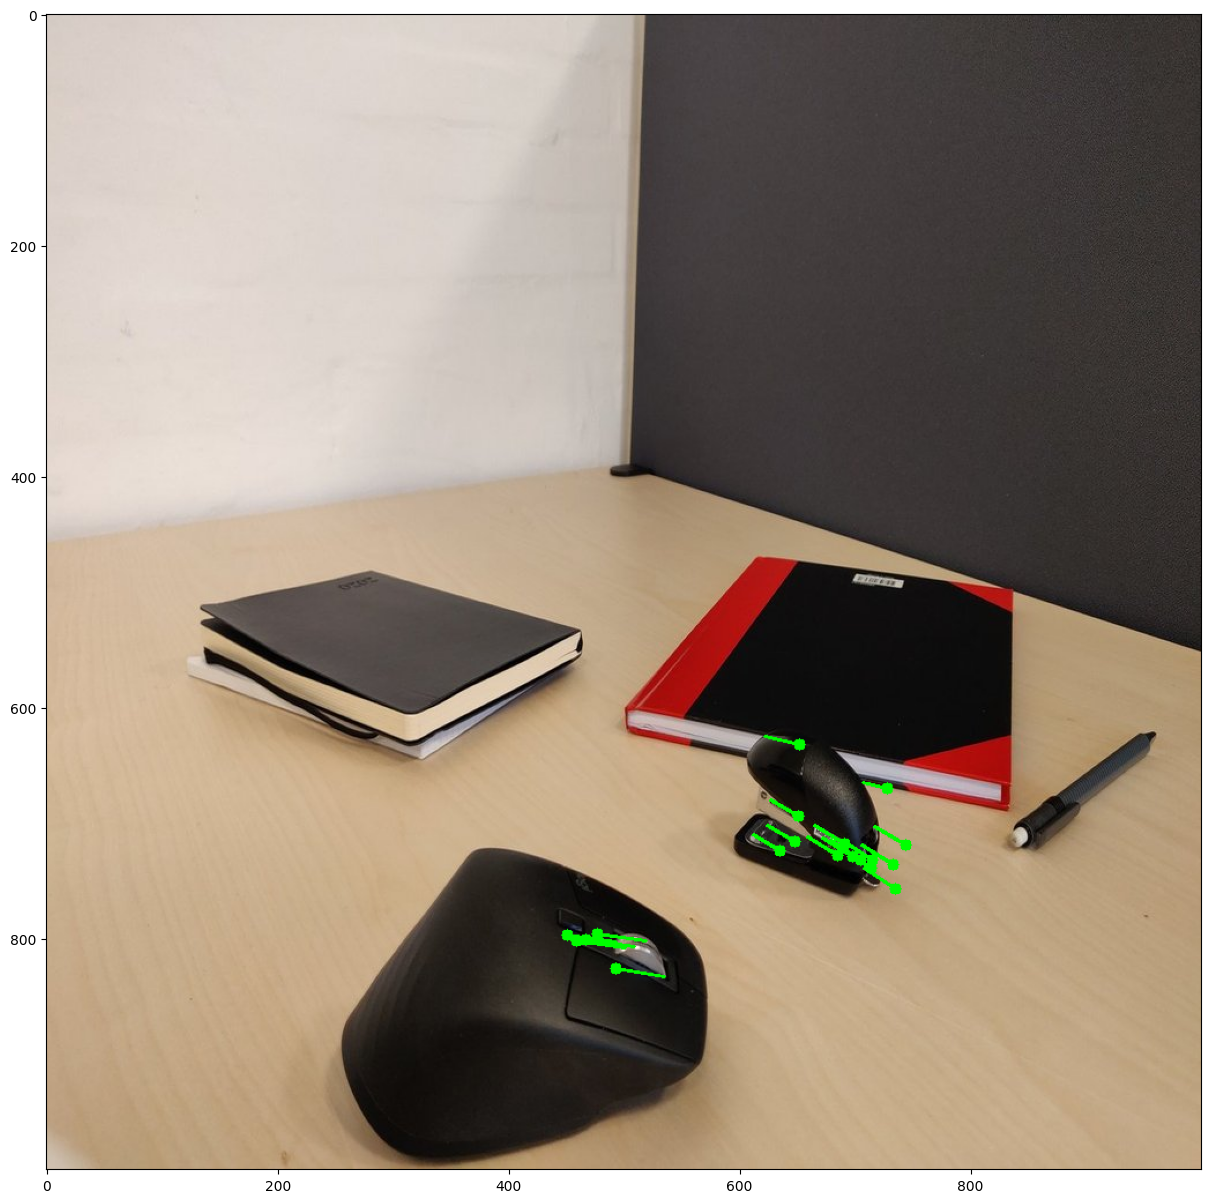

In [ ]:
# The previous cell draws every tracked feature regardless of how far it moved,
# which clutters the image with lines for points that barely moved or didn't
# move at all. Filtering by displacement highlights only the genuinely moving
# points. Reload a fresh copy of the second image ('img_viz') so we don't draw
# on top of the already-annotated 'img2' from the previous cell. For each
# feature, compute the Euclidean distance between its start and end position
# (basic distance formula: sqrt((dx)^2 + (dy)^2)), and only draw the line/circle
# if that distance exceeds a threshold of 10 pixels. This filters out features
# whose apparent "movement" is small enough to be tracking jitter rather than real motion.
img_viz = cv2.imread('OF2.jpg')

for i in range(len(feat1)):
    f10=int(feat1[i][0][0])
    f11=int(feat1[i][0][1])
    f20=int(feat2[i][0][0])
    f21=int(feat2[i][0][1])

    dist = ((f10 - f20) ** 2 + (f11 - f21) ** 2) ** 0.5

    if dist > 10:
        cv2.line(img_viz, (f10,f11), (f20, f21), (0, 255, 0), 2)
        cv2.circle(img_viz, (f10, f11), 5, (0, 255, 0), -1)

plt.figure(figsize=(15,15))
plt.imshow(cv2.cvtColor(img_viz, cv2.COLOR_BGR2RGB))

## Dense Optical Flow
The sparse optical flow finds the flow of the detected keypoints. We will now try to use dense optical flow which, finds the flow of all the points in the picture. 
For this example we use the same two images, so we don't have to load them again. To find the optical flow, we use the function [`cv2.calcOpticalFlowFarneback`](https://docs.opencv.org/4.7.0/dc/d6b/group__video__track.html#ga5d10ebbd59fe09c5f650289ec0ece5af). Check out the description to see what all the different parameters do, and try to change them to see the difference.

In [ ]:
# Compute dense optical flow using the Farneback method. Unlike calcOpticalFlowPyrLK,
# which only tracks a handful of selected feature points, cv2.calcOpticalFlowFarneback()
# estimates a motion vector for every single pixel in the image, giving a
# complete picture of how the whole scene moved. Useful when motion isn't
# limited to a few distinct trackable corners.
#   gray1, gray2: the two consecutive grayscale frames to compare.
#   None: no precomputed flow to initialize from.
#   pyr_scale=0.5: each pyramid level is half the resolution of the previous one.
#   levels=3: number of pyramid layers used, allowing the algorithm to estimate
#     both large and small motions.
#   winsize=15: size of the averaging window used when estimating motion at each
#     pixel (larger values give smoother, more robust flow but blur out fine
#     motion detail).
#   iterations=3: number of refinement iterations performed at each pyramid level.
#   poly_n=5 : size of the pixel neighborhood used to fit the polynomial
#   expansion the algorithm relies on internally.
#   poly_sigma=1.5: Gaussian smoothing used to stabilize that polynomial fit.
#   flags=0: no extra flags/optimizations enabled.
# The result 'flow' is an array the same width/height as the images, where each
# pixel holds a 2D (dx, dy) motion vector.
flow = cv2.calcOpticalFlowFarneback(gray1, gray2, None, 0.5, 3, 15, 3, 5, 1.5, 0)

The function returns an array containing the flow vector for every pixel. This can be changed to a magnitude and an angle using the function [`cv2.cartToPolar`](https://docs.opencv.org/4.7.0/d2/de8/group__core__array.html#gac5f92f48ec32cacf5275969c33ee837d). 

# Exercise 4b
Find a way to represent the flow in the image, for example, by drawing vectors the relevant places or by making a new image with colors representing the flow of every pixel. An example of retrieving the magnitude and angle is shown below, which you can use if you like. 

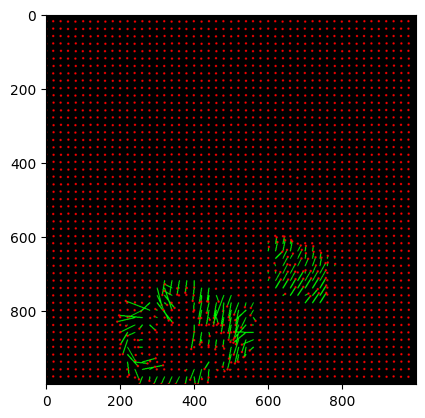

In [ ]:
# cv2.cartToPolar() converts each pixel's (dx, dy) flow vector into a
# (magnitude, angle) pair, which is often more intuitive to visualize directly.
# Magnitude tells us how much a point moved, angle tells us in which direction.
# Drawing a vector for every single pixel would be far too dense and unreadable,
# so we subsample the flow field on a coarse grid (every 20 pixels in each
# direction) and only draw a representative arrow for each sampled location.
#   - 'sam_mag'/'sam_ang' pick out just the magnitude/angle values at the sampled
#     grid locations.
#   - 'empty' is a blank black canvas (same size as the image, 3 color channels)
#     that the flow vectors will be drawn onto, rather than drawing over the
#     original image.
#   - 'start' builds a coordinate grid matching the sampled locations.
#   - 'end_point' computes where each vector should end, by moving from the start
#     location in the direction given by its angle and by a  distance given by
#     its magnitude (basic trigonometry: cos for the x/column displacement, sin
#     for the y/row displacement. Note the minus sign on the sine term accounts
#     for image row-coordinates increasing downward while a standard angle
#     convention increases counter-clockwise). np.clip() keeps the resulting
#     coordinates within the image bounds so we don't try to draw outside the canvas.
#   - The nested loop then draws, for every sampled grid point, a green line
#     from its start position to its computed end position (showing the
#     direction/magnitude of motion there) plus a small red circle marking the endpoint.
# Retrieving the magnitude and angle of every pixel.
mag, ang = cv2.cartToPolar(flow[:,:,0], flow[:,:,1])

sampling = 20

### Fill in some code to represent the flow here ###
sam_mag, sam_ang = mag[::sampling, ::sampling], ang[::sampling, ::sampling]

empty = np.zeros(shape=(mag.shape[0], mag.shape[1], 3), dtype=np.uint8)

start = np.mgrid[0:1000:sampling, 0:1000:sampling]

end_point = (
    np.clip(np.squeeze(start[0, ...]) + sam_mag * np.cos(sam_ang), 0, 1000),
    np.clip(np.squeeze(start[1, ...]) - sam_mag * np.sin(sam_ang), 0, 1000)
)

for i in range(sam_mag.shape[0]):
    for j in range(sam_mag.shape[1]):
        cv2.line(empty, (j * sampling, i * sampling), (int(end_point[1][i, j]), int(end_point[0][i, j])), (0, 255, 0), 2)
        cv2.circle(empty, (int(end_point[1][i, j]), int(end_point[0][i, j])), 3, (0, 0, 255), -1)

plt.imshow(cv2.cvtColor(empty, cv2.COLOR_BGR2RGB))
